# Code walkthrough

`tiny_lie` is a from-scratch implementation built to understand the machinery of the 3D rotation group $SO(3)$.

$SO(3)$ can be represented two ways in code:
- directly as special orthogonal 3x3 matrices,
- or via unit quaternions ($S^3$, the double cover of $SO(3)$).

Both are implemented here. More precisely:
- `class SO3` implements $SO(3)$,
- `class UnitQuaternion` implements its double cover $S^3$, which maps onto $SO(3)$ 2-to-1 ($q$ and $-q$ representing the same rotation).
 
We will discuss the classes' methods `Exp/Log` that implement the Exp and Log maps operating on each group's Lie algebra, namely
- for $SO(3)$, the set of antisymmetric matrices $\mathfrak{so}(3)$,
- for $S^3$, the set of pure quaternions $\mathbb{H}_p$ (or $\mathfrak{su}(2)$).
  
Both Lie algebras are 3-dimensional and naturally parameterized by the same rotation vector $\boldsymbol\tau = \theta\mathbf u \in \mathbb{R}^3$ (axis $\mathbf u$, angle $\theta = \lVert\boldsymbol\tau\rVert$, and `Vec3` in the implementations).
Numerical aspects of their implementations will be discussed.

Operators right-$\oplus$ and right-$\ominus$ are illustrated with a toy example: Rotation averaging via iterative tangent-space averaging.

In [3]:
from lie import Vec3, SO3, UnitQuaternion
import numpy as np
import matplotlib.pyplot as plt

## The group of unit quaternions $S^3$

$$
S^3 = \{\, q = (w, \mathbf{v}) \in \mathbb{H} \ :\ \lVert q \rVert = 1 \,\}, \qquad
\mathfrak{su}(2) = \mathbb{H}_p = \{\, (0, \mathbf{v}) \ :\ \mathbf{v} \in \mathbb{R}^3 \,\}.
$$

The group $S^3$ (unit quaternions) acts on $\mathbb{R}^3$ by rotation, $\mathbf{p} \mapsto q\,\mathbf{p}\,q^*$. Its Lie algebra is the pure quaternions $\mathbb{H}_p \cong \mathbb{R}^3$, the tangent space at the identity (the Lie algebra, a vector space with extra structure we set aside for now), where rotation vectors can be added and scaled, as the averaging below relies on.

`Exp` and `Log` map between them: `Exp` builds the unit quaternion from a rotation vector, `Log` recovers the rotation vector.


### Exp: $\mathfrak{su}(2) \to S^3$

In [21]:
from IPython.display import Code
Code(inspect.getsource(UnitQuaternion.Exp), language='python')

@classmethod
    def Exp(cls, tau: Vec3) -> UnitQuaternion:
        theta = tau.norm()
        if theta < EPS: # small angles
            return cls(1-theta*theta/8, tau/2) # Taylor expansions of cos(theta/2) and sin(theta/2)/theta
        else:
            return cls(math.cos(theta/2), tau*math.sin(theta/2)/theta)

The rotation vector $\boldsymbol\tau = \theta\mathbf{u}$ maps to the unit quaternion

$$q = \left(\cos\tfrac\theta2,\ \mathbf u\,\sin\tfrac\theta2\right).$$

(Each rotation has two representatives, $q$ and $-q$ — the double cover $S^3 \to SO(3)$.)

For small angles, $\frac{\theta}{\sin(\theta/2)} \to 2$. 

### Log: $S^3 \to \mathfrak{su}^2$


In [19]:
Code(inspect.getsource(UnitQuaternion.Log), language='python')

def Log(self) -> Vec3:
        vnorm = self._v.norm()
        if vnorm < EPS: # small angles
            f = 2  # Taylor expansion of theta/sin(theta/2)
        else:
            f = 2*math.atan2(vnorm, self._w)/vnorm
        return f*self._v



From the quaternion $q$, `Log` recovers the rotation vector $\boldsymbol\tau = \theta\mathbf{u}$

By identifying real and imaginary parts
$$
q=(w,\mathbf{v}) = (\cos(\theta/2), \mathbf{u} \sin(\theta/2)),
$$
we deduce
$$
\begin{aligned}
\text{Angle:} \quad \theta &= 2\operatorname{arctan2}(\sin(\theta/2),\, \cos(\theta/2)) \\
                           &= 2\operatorname{arctan2}(\lVert\mathbf{v}\rVert,\, w) \\[4pt]
\text{Rotation vector:} \quad \boldsymbol{\tau} &= \theta \mathbf{u} = \frac{\theta}{\sin(\theta/2)} \mathbf{v}.
\end{aligned}
$$
For numerical stability, we use the Taylor expansion $\frac{\theta}{\sin(\theta/2)} \to 2$ when $\theta \to 0$. 




### The numerical case for arctan2

Why use $\operatorname{arctan2}$ over the other inverse trigonometric functions?
Why not compute $\theta$ as $2\arccos(w)$, or $2\arcsin(\lVert\mathbf{v}\rVert)$, or $2\arctan(\lVert\mathbf{v}\rVert / w)$?

The derivatives of $\arccos(x)$ ($\frac{-1}{\sqrt{1-x^2}}$) and $\arcsin(x)$ ($\frac{1}{\sqrt{1-x^2}}$) blow up near $x=\pm 1$ (i.e. for small angles and angles near $\pi$). Round-off errors in $w$ or $\lVert\mathbf{v}\rVert$ then get amplified unboundedly in the estimate of $\theta$.

The derivative of $\arctan(x)$ ($\frac{1}{1+x^2}$) is smooth and bounded, but the ratio $\lVert\mathbf{v}\rVert / w$ goes to infinity as $w\to 0$ (angles near $\pi$), leading to a `nan`.

On the other hand the two partial derivatives of $\psi = \operatorname{arctan2}(y,x) = \arctan(y/x)$ are

$$
\frac{\partial\psi}{\partial y} = \frac{x}{x^2+y^2},
\qquad
\frac{\partial\psi}{\partial x} = \frac{-y}{x^2+y^2}.
$$

With the real and imaginary parts of our unit quaternion as arguments ($x=w$, $y=\lVert\mathbf{v}\rVert$, and using $w^2+\lVert\mathbf{v}\rVert^2=1$), the sensitivity of $\theta = 2\psi$ is

$$
\begin{aligned}
\frac{\partial\theta}{\partial w} &= -2\lVert\mathbf{v}\rVert, \qquad |\cdot|\le 2 \\[4pt]
\frac{\partial\theta}{\partial \lVert\mathbf{v}\rVert} &= 2w, \qquad\ \ |\cdot|\le 2
\end{aligned}
$$

Both are bounded by $2$ on the unit sphere, and they trade off: $\frac{\partial\theta}{\partial w} = -2\lVert\mathbf{v}\rVert \to 0$ near $\theta=0$ (the angle is read from $\lVert\mathbf{v}\rVert$), while $\frac{\partial\theta}{\partial \lVert\mathbf{v}\rVert} = 2w \to 0$ near $\theta=\pi$ (read from $w$). There is no value of $\theta$ where angle recovery is ill-conditioned.

> The identity $\operatorname{arctan2}(y,x)=\arctan(y/x)$ (up to quadrant) is used here only to take derivatives. Libraries implement $\operatorname{arctan2}$ as a dedicated primitive that avoids the division $y/x$, undefined at $x=0$.





## The group of 3x3 orthogonal matrices $SO(3)$


Another representation for the same rotation group is the Lie group of 3x3 rotation matrices $SO(3)$.

Its Lie algebra $so(3)$ is the set of 3x3 antisymetric matrices, fully parameterized by a rotation vector $\boldsymbol\tau$, via the operator $\hat{\boldsymbol\tau} = [\boldsymbol\tau]_x$.

Observe that the elements of the Lie algebra can be seen as the rotation vector representation of that rotation.





### Exp: $\mathfrak{so}(3) \to SO(3)$

In [18]:
Code(inspect.getsource(SO3.Exp), language='python')

@classmethod
    def Exp(cls, tau: Vec3) -> SO3:
        angle = tau.norm()
        I = np.eye(3)
        if angle < EPS:
            # sin theta / theta -> 1
            # (cos theta - 1) -> 0
            T = cls.hat(tau)
            R = I + T 
        else:
            # rodrigues
            U = cls.hat(tau/angle)
            c = math.cos(angle)
            s = math.sin(angle)
            R = I + s*U + (1-c)*(U@U)
        return cls(R)

For a rotation vector $\boldsymbol\tau = \theta\mathbf{u} \in \mathbb{R}^3$, the exponential map builds the rotation matrix via **Rodrigues' formula**:

$$
R = I + \sin\theta\,[\mathbf{u}]_\times + (1-\cos\theta)\,[\mathbf{u}]_\times^2, \qquad \theta = \lVert\boldsymbol\tau\rVert.
$$

This is $\exp([\boldsymbol\tau]_\times)$, the matrix exponential of the skew-symmetric $[\boldsymbol\tau]_\times$, the same rotation as the quaternion $\mathrm{Exp}(\boldsymbol\tau)$ above, in a different representation.

For small angles, $\sin\theta/\theta \to 1$ and $(1-\cos\theta) \to 0$, so $R \to I + [\boldsymbol\tau]_\times$ (first order), using $\boldsymbol \tau$ directly in the branch taken below $\varepsilon$ to avoid dividing by $\theta \to 0$.

### Log: $SO(3) \to \mathfrak{so}(3)$

In [20]:
Code(inspect.getsource(SO3.Log), language='python')

def Log(self) -> Vec3:
        t = self.vee(self._R-self._R.T)/2
        sinA = t.norm()  # assuming sinA >= 0 w.l.g.
        cosA = (self._R.trace()-1)/2
        angle = math.atan2(sinA, cosA)
        if angle < EPS:
            tau = t
        elif EPS < angle < math.pi-EPS:
            tau = angle/sinA*t
        else: # angle ~ pi
            A = (self._R + np.eye(3))/2  # ~= u @ u^T
            max_idx = np.argmax(np.diag(A))
            u = A[:,max_idx]/sqrt(A[max_idx, max_idx])
            tau = angle * Vec3(*u)
        return tau

`Log` recovers the rotation vector $\boldsymbol\tau = \theta\mathbf{u}$ from $R$.

The angle comes from the trace, $\mathrm{tr}(R) = 1 + 2\cos\theta$, and the axis from the antisymmetric part, $R - R^\top = 2\sin\theta\,[\mathbf{u}]_\times$:

$$
\theta = \operatorname{arctan2}\!\big(\lVert \operatorname{vee}(R - R^\top)/2 \rVert,\ \tfrac{\mathrm{tr}(R) - 1}{2}\big),
\qquad
\boldsymbol\tau = \frac{\theta}{2\sin\theta}\,\operatorname{vee}(R - R^\top).
$$

As with the quaternion, $\operatorname{arctan2}$ (using both the $\sin$ and $\cos$ parts) is preferred over $\arccos$ of the trace alone.

Two corner cases need separate handling:
- **$\theta \to 0$** (small angle): $\theta/(2\sin\theta) \to 1/2$, Taylor branch, avoids dividing by $\sin\theta \to 0$.
- **$\theta \to \pi$**: the antisymmetric part $R - R^\top \to 0$ loses the axis, so it is recovered from the symmetric part $(R + I)/2 \approx \mathbf{u}\mathbf{u}^\top$ instead. (At $\theta = \pi$, $+\boldsymbol\tau$ and $-\boldsymbol\tau$ are the same rotation, that's sign ambiguity resulting from the double-coverage.)

## Toy example 1 - Rotation averaging


The right-plus and right-minus operators move between the group and its tangent space:

$$
X \oplus \boldsymbol\tau = X \circ \mathrm{Exp}(\boldsymbol\tau), \qquad
Y \ominus X = \mathrm{Log}(X^{-1} \circ Y).
$$

$\oplus$ applies a local-frame increment $\boldsymbol\tau$ to a rotation; $\ominus$ returns the increment (in $X$'s local frame) that takes $X$ to $Y$. They are inverse operations: $(X \oplus \boldsymbol\tau) \ominus X = \boldsymbol\tau$.

%--todo: notes from figure 7 --

In [25]:
Code(inspect.getsource(SO3.rplus), language='python')

def rplus(self, tau: Vec3) -> SO3:
        return self * SO3.Exp(tau)   # R o Exp(tau), R cirlePlus tau

In [24]:
Code(inspect.getsource(SO3.rminus), language='python')

def rminus(self, other: SO3) -> Vec3:
        return (other.inverse() * self).Log()
        # returns the local-frame tangent
        #    at 'other' that reaches 'self'
        # convention:
        #  - self is the left operand
        #  - Y circleMinus X
        #    Y[self].rminus(X[other])
        #    Log (Xinv o Y)
        #    Log(other.inv * self)

### The Fréchet (Karcher) mean

Given rotations $R_1, \dots, R_N$, the **Fréchet mean** $\mu$ minimizes the sum of squared geodesic distances:

$$
\mu = \arg\min_{\mu} \ \tfrac12 \sum_i \lVert R_i \ominus \mu \rVert^2.
$$

The geodesic distance is $\lVert R_i \ominus \mu \rVert = \lVert \mathrm{Log}(\mu^{-1} R_i) \rVert$, the angle between the two rotations. Unlike the Euclidean mean, this has no closed form on $SO(3)$, so we solve it iteratively.

The gradient (in the tangent space at $\mu$) is

$$
\nabla = -\sum_i (R_i \ominus \mu),
$$

so a gradient step with step size $1/N$ gives the update

$$
\mu \ \leftarrow\ \mu \oplus \frac{1}{N}\sum_i (R_i \ominus \mu).
$$

Each iteration: measure the tangent vectors from the current estimate to every rotation ($\ominus$), average them, and step the estimate along that average ($\oplus$). The sum of tangent vectors vanishes at the mean — the manifold analogue of $\sum_i (x_i - \bar x) = 0$.

In [13]:
    # synthetic data (100 Gaussian corruptions of R_true)
    rng = np.random.default_rng(0)
    R_true = SO3.Exp(Vec3(0.5, -0.3, 0.8))
    rots = [R_true.rplus(Vec3(*(0.1 * rng.normal(size=3)))) for _ in range(100)]

    # Estimate Karcher(?) mean
    mu = rots[0]
    step_sizes, errors = [], []
    for _ in range(20):
        # distances
        taus = [rot.rminus(mu) for rot in rots]
        tau = sum(taus, Vec3(0., 0., 0.)) / len(rots)
        # graph data gathering
        step_sizes.append(tau.norm())
        errors.append(mu.rminus(R_true).norm())  
        # update
        mu = mu.rplus(tau)

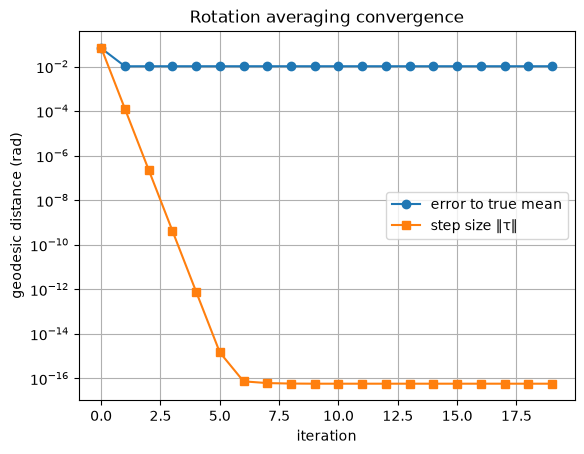

In [14]:
plt.semilogy(errors, marker='o', label='error to true mean')
plt.semilogy(step_sizes, marker='s', label='step size ‖τ‖')
plt.xlabel('iteration'); plt.ylabel('geodesic distance (rad)')
plt.title('Rotation averaging convergence'); plt.legend(); plt.grid(True)
plt.show()